In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

## Exercise 1
a) Load house sales data from file kc_house_data.csv, print first records.  
b) Print the variable list. Select categorical and numerical variables.  
c) Compute basic statistics of numerical variables. Are all of them meaningful?

Let's look at the first few records of the dataset:

In [ ]:
#a)

# read file (df - dataframe)
df = pd.read_csv("kc_house_data.csv")

# show the first few records
df.head()


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


It is interesting to observe that:
- the number of bathrooms doesn't have to be an integer (since 0.5 accounts for a room with a toilet but no shower)
- if a house hasn't been renovated, the year of its renovation is 0

In [ ]:
#b)

# change type of selected columns to 'category'
# otherwise it could lead to misleading results if treated as numerical
cols_to_cat = ["id", "waterfront", "view", "condition", "grade", "yr_renovated", "zipcode"]
df[cols_to_cat] = df[cols_to_cat].astype("category")

# select categorical and numerical variables
house_categorical_df = df.select_dtypes(include=["object", "category"]).columns.tolist()
house_numerical_df = df.select_dtypes(include=[np.number]).columns.tolist()

# show results
print(f"Categorical variables: {house_categorical_df}")
print(f"Numerical variables: {house_numerical_df}\n")


Categorical variables: ['id', 'date', 'waterfront', 'view', 'condition', 'grade', 'yr_renovated', 'zipcode']
Numerical variables: ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'sqft_above', 'sqft_basement', 'yr_built', 'lat', 'long', 'sqft_living15', 'sqft_lot15']



The analysis of some given numerical variables could potentially end up in misleading results, so in order to avoid that **they had to be changed to function like a categorical variable.**

It applies to the following variables:
- "id" - unique ID for each home sold
- "waterfront" - a dummy variable for whether the apartment was overlooking the waterfront or not
- "view" - an index from 0 to 4 of how good the view of the property was
- "condition" - an index from 1 to 5 on the condition of the apartment,
- "grade" - an index from 1 to 13, where 1-3 falls short of building construction and design, 7 has an average level of construction and design, and 11-13 have a high quality level of construction and design.
- "yr_renovated" - the year of the house’s last renovation
- "zipcode" - what zipcode area the house is in

Below there is a table of the basic statistics of numeral variables from the dataset

In [ ]:
#c)

# generate basic statistics of numerical variables
df[house_numerical_df].describe()


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,sqft_above,sqft_basement,yr_built,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,1788.390691,291.509045,1971.005136,47.560053,-122.213896,1986.552492,12768.455652
std,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,828.090978,442.575043,29.373411,0.138564,0.140828,685.391304,27304.179631
min,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,290.000000,0.000000,1900.000000,47.155900,-122.519000,399.000000,651.000000
25%,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,1190.000000,0.000000,1951.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,1560.000000,0.000000,1975.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,2210.000000,560.000000,1997.000000,47.678000,-122.125000,2360.000000,10083.000000
max,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,9410.000000,4820.000000,2015.000000,47.777600,-121.315000,6210.000000,871200.000000


**Are all of these statistics meaningful?**\
**No**,
treating 'lat' and 'long' variables independently can lead to misleading results:
* combining their means or percentiles can result in an obscure location, such as in the mountains or in the middle of a lake
* they have no direct linear effect on the price, which is correlated more with the distance to the city centre, schools etc.
* their standard deviation is given in degrees, in which case the actual distance depends on the other variable (distance of 1 degree of longitude depends on the lattitude etc)

... so there is no reason to analyze them apart from each other



## Exercise 2
Using scatter plot:  
a) Show the relation of square footage and price.  
b) Check how price is influenced by apartment's grade. Find other variables correlated with price.  
c) Check how good apartments are distributed over the city. First, plot zipcode versus price. Then, use apartments coordinates (longitude and lattitude) in order to show where apartments of good grade are located.

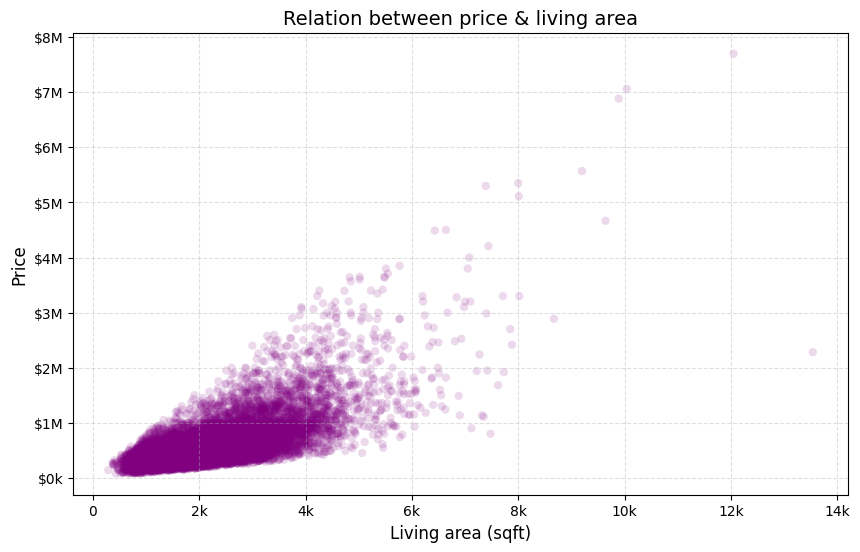

In [ ]:
#a)

# set size of the figure
plt.figure(figsize=(10, 6))

# define how to change units of price
def format_price(x, pos):
  if x >= 1_000_000:
    return f"${x*1e-6:.0f}M"
  else:
    return f"${x*1e-3:.0f}k"

# define how to change units of square feet
def format_sqft(x, pos):
  if x >= 1_000:
    return f"{x*1e-3:.0f}k"
  else:
    return f"{x*1e-0:.0f}"

# create scatter plot
plt.scatter(
    df["sqft_living"],
    df["price"],
    alpha=0.15,
    color="purple",
    edgecolors="none"
)

# set unit of x-axis and y-axis
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(format_sqft))
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# scatter plot settings
plt.title("Relation between price & living area", fontsize=14)
plt.xlabel("Living area (sqft)", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


As can be seen on the graph above, the price is positively correlated with the square footage of the apartments interior living space (described as living area). However, the relation is not strictly proportional, as the general price of apartments rises more slowly than the square footage of living area. This is a good piece of information for potential clients wanting to buy a new house.

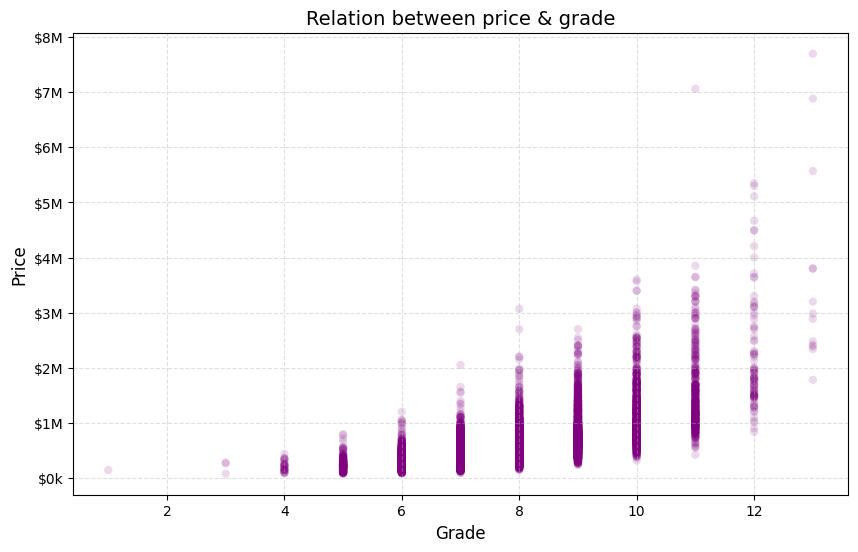

In [ ]:
#b)

# set size of the figure
plt.figure(figsize=(10, 6))

# create scatter plot
plt.scatter(
    df["grade"],
    df["price"],
    alpha=0.15,
    color="purple",
    edgecolors="none"
)

# set unit of y-axis
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# scatter plot settings
plt.title("Relation between price & grade", fontsize=14)
plt.xlabel("Grade", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


As can be seen on the graph above, the price is also positively correlated with the grade of the house (subjective measure of its construction and design). Moreover, as the house grade goes higher, the price range of the houses also increases significantly. There is a chance to buy a house having a better grade with only a slight increase in price, so it is cohesive with the observations described earlier.

The following data has been created in an attempt to find other variables, which are also correlated with price.

The first attempt was finding whether the price is correlated with when the house was built (assuming that perhaps relatively recently built houses are more expensive than the older ones).

Below there are basic statistics of the column 'year built'.

In [ ]:
print(f"Mean of year built: {df['yr_built'].mean():.0f}")
print(f"Median of year built: {df['yr_built'].median():.0f}")
print(f"Min of year built: {df['yr_built'].min():.0f}")
print(f"Max of year built: {df['yr_built'].max():.0f}")

Mean of year built: 1971
Median of year built: 1975
Min of year built: 1900
Max of year built: 2015


Mean of year built is lower than the median, which means that a small subset of buildings has been built much earlier than the rest of the houses in the dataset. As can be seen above, the first house from the dataset has been built in 1900.



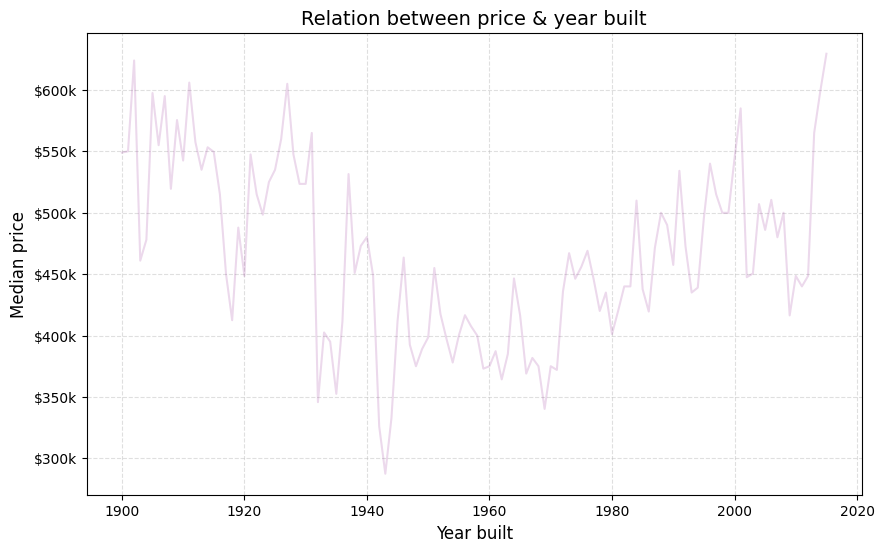

In [ ]:
# set size of the figure
plt.figure(figsize=(10, 6))

# calculate median for each year built
median_price = df.groupby('yr_built')['price'].median().reset_index()

# create plot
plt.plot(
    median_price["yr_built"],
    median_price["price"],
    alpha=0.15,
    color="purple"
)

# set unit of y-axis
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# scatter plot settings
plt.title("Relation between price & year built", fontsize=14)
plt.xlabel("Year built", fontsize=12)
plt.ylabel("Median price", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


As can be seen on the graph above, the median price of houses built in each year is not correlated with when the house has been built.

This time, we want to check whether the price is correlated with the number of bedrooms that the house has.

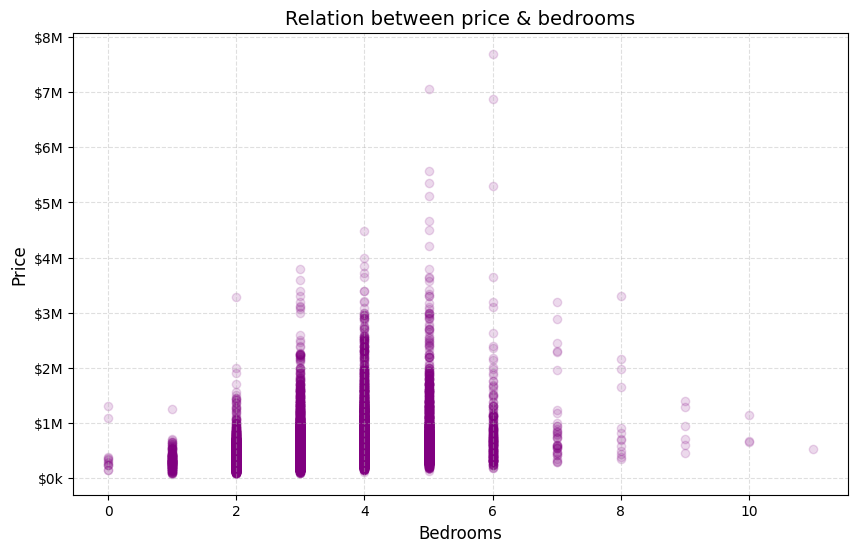

In [ ]:
# set size of the figure
plt.figure(figsize=(10, 6))

# ignore outliers with more than 13 bedrooms
df_valid = df[df["bedrooms"] < 13]

# create scatter plot
plt.scatter(
    df_valid["bedrooms"],
    df_valid["price"],
    alpha=0.15,
    color="purple"
)

# set unit of y-axis
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# scatter plot settings
plt.title("Relation between price & bedrooms", fontsize=14)
plt.xlabel("Bedrooms", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


As can be seen on the graph above, the price is correlated with the number of bedrooms until there are around 5 bedrooms in the house. In the case of larger houses, such an observation cannot be made - their price is decreasing again possibly due to other factors.

In the next step, we would like to find out whether there is a similar correlation in the case of number of bathrooms in the house.

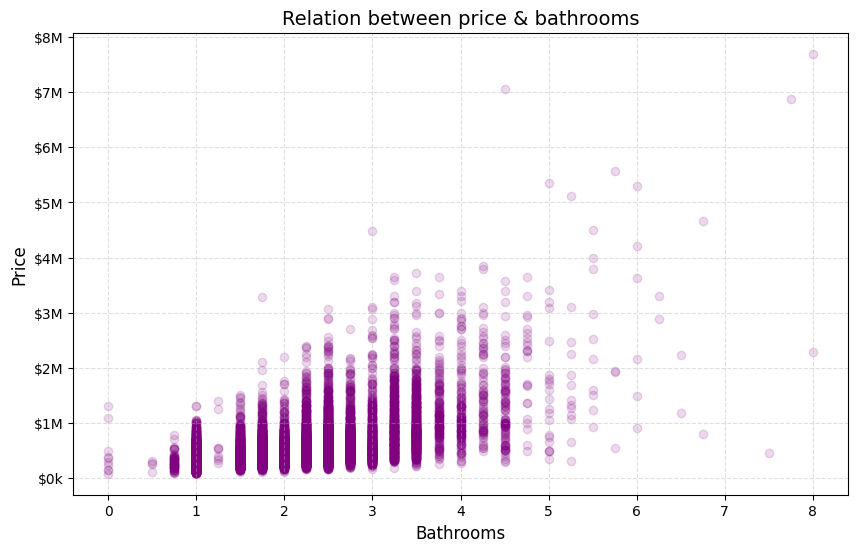

In [ ]:
# set size of the figure
plt.figure(figsize=(10, 6))

# ignore outliers with more than 13 bedrooms
df_valid = df[df["bedrooms"] < 13]

# create scatter plot
plt.scatter(
    df_valid["bathrooms"],
    df_valid["price"],
    alpha=0.15,
    color="purple"
)

# set unit of y-axis
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# scatter plot settings
plt.title("Relation between price & bathrooms", fontsize=14)
plt.xlabel("Bathrooms", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


As can be seen on the graph above, there seems to be a positive correlation between the price of the house and the number of bathrooms that it has. Again, it can be observed until there are about 4-5 bathrooms in the house.

(Reminder: 0.5 bathrooms accounts for a room with a toilet but no shower)

Since the price was positively correlated with the square footage of interior living space, we might make an assumption that this correlation also holds up when it comes to square footage available above ground level.

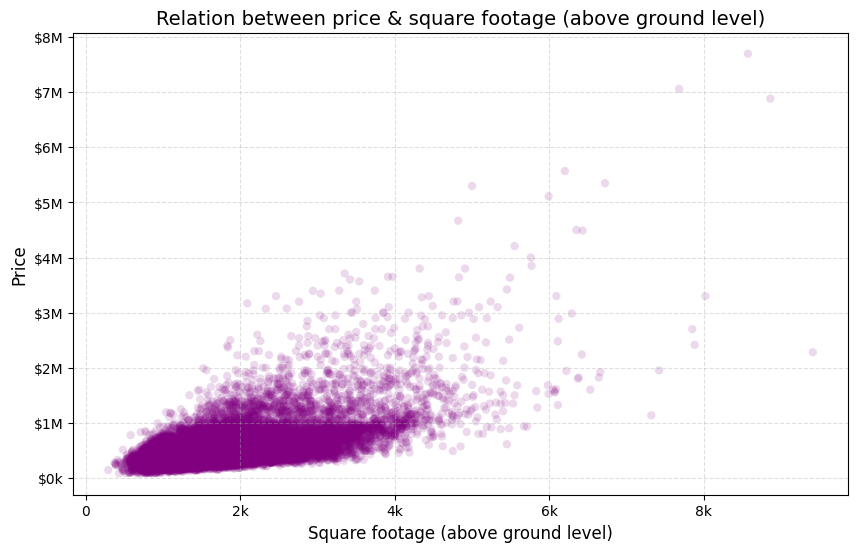

In [ ]:
# set size of the figure
plt.figure(figsize=(10, 6))

# create scatter plot
plt.scatter(
    df["sqft_above"],
    df["price"],
    alpha=0.15,
    color="purple",
    edgecolors="none"
)

# set unit of x-axis and y-axis
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(format_sqft))
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# scatter plot settings
plt.title("Relation between price & square footage (above ground level)", fontsize=14)
plt.xlabel("Square footage (above ground level)", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


As can be seen on the graph above, the assumption was correct and price of the house is positively correlated with the square footage available above ground level. Again, the relation is not strictly proportional (like it was when it comes to interior living space), as the general price of apartments rises more slowly than the square footage above ground level.

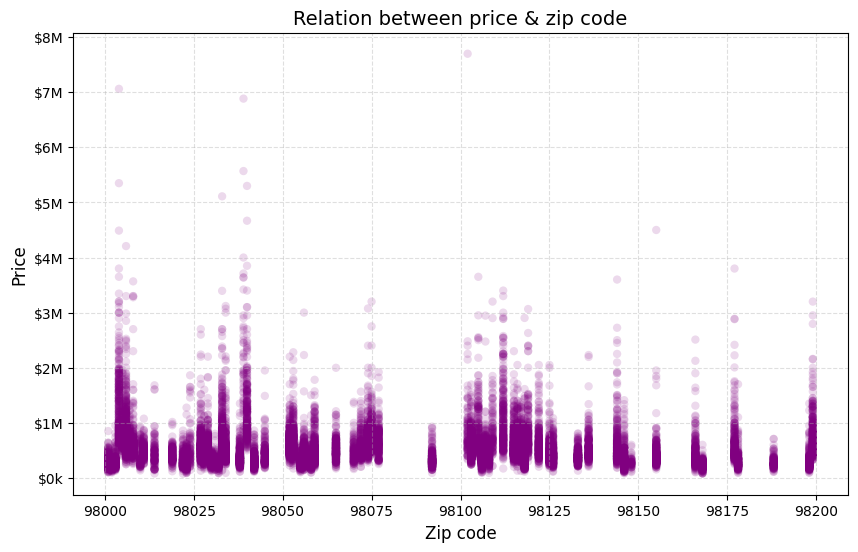

In [ ]:
#c)

# set size of the figure
plt.figure(figsize=(10, 6))

# create scatter plot
plt.scatter(
    df["zipcode"], df["price"], alpha=0.15, color="purple", edgecolors="none"
)

# set unit of y-axis
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# scatter plot settings
plt.title("Relation between price & zip code", fontsize=14)
plt.xlabel("Zip code", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


The most expensive houses have zipcodes around 98000, 98040 and between 98100-98125. It suggests that these are the locations that are favored by the citizens, possibly due to close proximity to large office areas, most prestigious schools, huge shopping malls etc. Moreover, it is a common heuristic that zipcodes allocation starts within the city center, what is also slightly reflected in this graph.

Let's look at the map showing where the houses with the highest grades (11-13) are located:

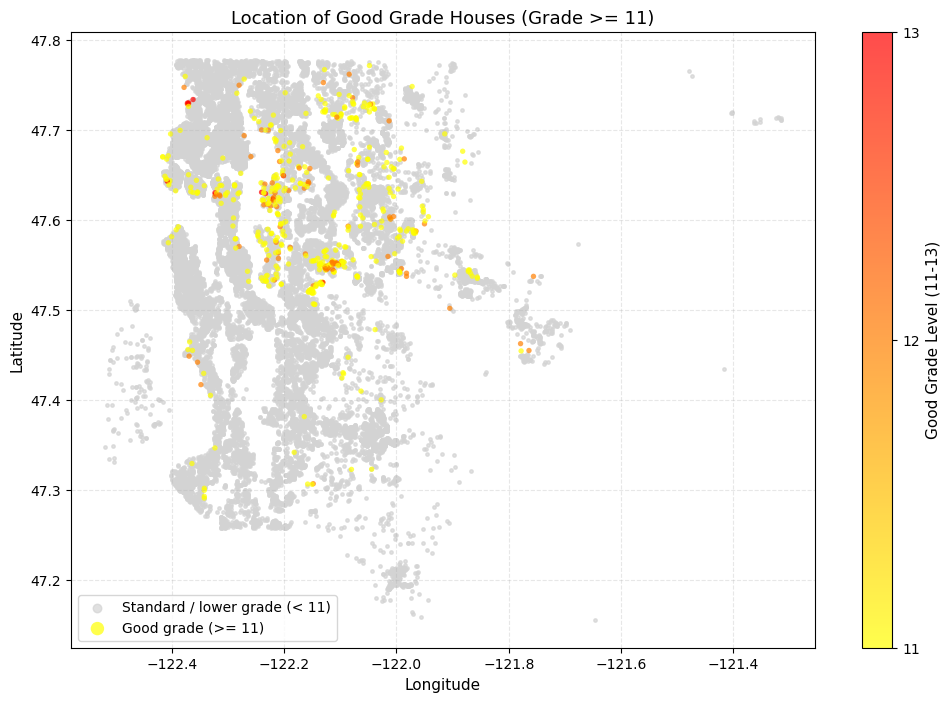

In [ ]:
# convert category grade to int
grade_num = df["grade"].astype(int)

# divide houses into standard & good grade (with threshold)
threshold = 11
other_houses = df[grade_num < threshold]
good_houses = df[grade_num >= threshold]

# set size of the figure
plt.figure(figsize=(12, 8))

# standard / lower grade houses
plt.scatter(
    other_houses["long"],
    other_houses["lat"],
    color="#d3d3d3",
    alpha=0.7,
    s=6,
    label=f"Standard / lower grade (< {threshold})",
)

# good grade houses with color intensity
scatter = plt.scatter(
    good_houses["long"],
    good_houses["lat"],
    c=good_houses["grade"].astype(int),
    cmap="autumn_r",
    alpha=0.7,
    s=15,
    edgecolors="none",
    label=f"Good grade (>= {threshold})",
)

# create colorbar for good grade houses
cbar = plt.colorbar(scatter)
cbar.set_label(f"Good Grade Level ({threshold}-13)", fontsize=11)

# set colorbar ticks to change every 1 grade
cbar.set_ticks(range(threshold, 14))

# other scatter plot settings
plt.title(
    f"Location of Good Grade Houses (Grade >= {threshold})",
    fontsize=13,
)

plt.xlabel("Longitude", fontsize=11)
plt.ylabel("Latitude", fontsize=11)
plt.legend(loc="lower left", markerscale=2.5)
plt.grid(True, linestyle="--", alpha=0.3)

plt.show()


As can be seen on the map above, houses with the highest quality level of construction and design are scattered across a lot of parts of the city. Most of these kind of houses tend to be built in clusters, with the largest one located in the city center.

Most of the houses from this category have grade 11.

Now let's look at the location of the most expensive houses (75th percentile):

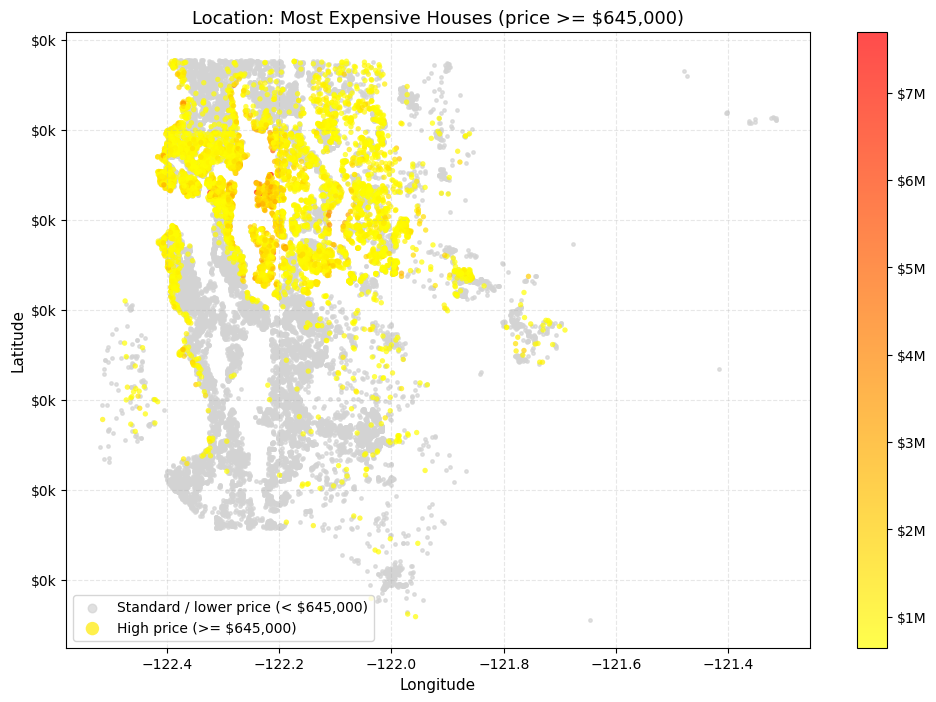

In [147]:
# divide houses into standard & high price (with threshold)
threshold = df["price"].quantile(0.75).round()
other_houses = df[df["price"] < threshold]
good_houses = df[df["price"] >= threshold]

# set size of the figure
plt.figure(figsize=(12, 8))

# standard / lower price houses
plt.scatter(
    other_houses["long"],
    other_houses["lat"],
    color="#d3d3d3",
    alpha=0.7,
    s=6,
    label=f"Standard / lower price (< ${threshold:,.0f})",
)

# high price houses with color intensity
scatter = plt.scatter(
    good_houses["long"],
    good_houses["lat"],
    c=good_houses["price"],
    cmap="autumn_r",
    alpha=0.7,
    s=15,
    edgecolors="none",
    label=f"High price (>= ${threshold:,.0f})",
)

# create colorbar for the most expensive houses
cbar = plt.colorbar(scatter)
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# set unit of y-axis
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# other scatter plot settings
plt.title(
    f"Location: Most Expensive Houses (price >= ${threshold:,.0f})",
    fontsize=13,
)

plt.xlabel("Longitude", fontsize=11)
plt.ylabel("Latitude", fontsize=11)
plt.legend(loc="lower left", markerscale=2.5)
plt.grid(True, linestyle="--", alpha=0.3)

plt.show()


As can be seen on the map above, the most expensive houses are located in the city center.

Other expensive houses that are located further from the city centre probably have other advantages (like square footage etc.)

## Exercise 3
a) Create boxplot of apartment's grade versus its price. Compare with plot 2b).  
b) Create mosaic plot of any two categorical variables.

Below there is a box plot of aparment's grade versus its price.

Here is what each of the aspect represents:

- light pink box range: interquartile range (IQR = Q3 - Q1)
  - where Q1 is 25th percentile and Q3 is 75th percentile
- solid horizontal lines after vertical dashed lines:
  - "minimum": Q1 - 1.5 * IQR
  - "maximum": Q3 + 1.5 * IQR
- solid bold pink line: median value
- gray dots: outliers

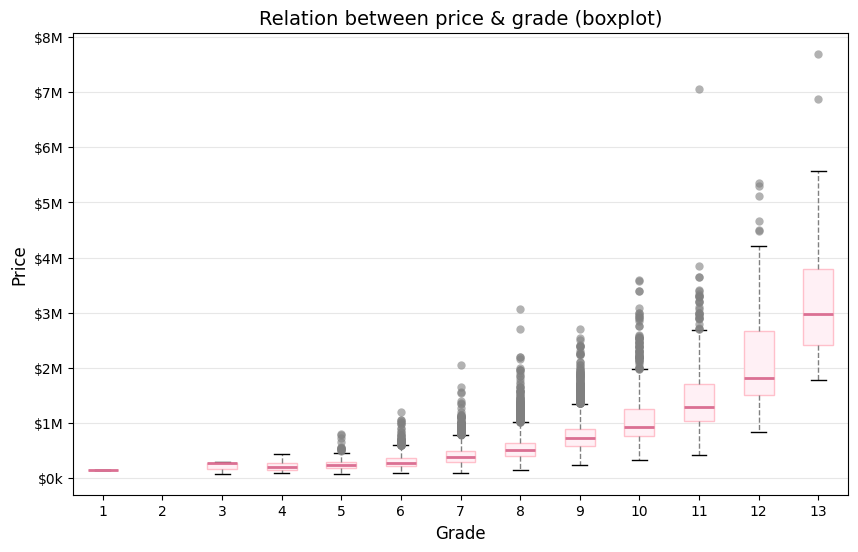

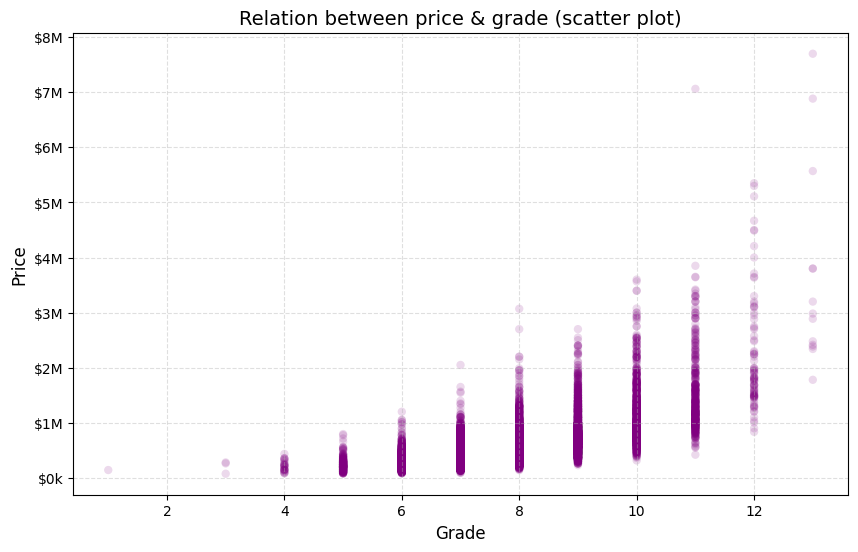

In [ ]:
#a)

# set size of the figure
plt.figure(figsize=(10, 6))

# sort grades in ascending order
grades = sorted(df["grade"].astype(int).unique())

# get all house prices for each grade
all_grades = list(range(1, 14))
price_groups = [
    df[df["grade"].astype(int) == g]["price"] for g in all_grades
]

# boxplot styling
fliers_style = dict(
    # marker="o",
    markerfacecolor="gray",
    markeredgecolor="none",
    # markersize=4,
    alpha=0.6
)

box_style = dict(facecolor="lavenderblush", color="pink", linewidth=1)
median_style = dict(color="palevioletred", linewidth=2)
whisker_style = dict(color="gray", linestyle="--")
cap_style = dict(color="black", linewidth=1)

# create boxplot
plt.boxplot(
    price_groups,
    tick_labels=all_grades,
    patch_artist=True,          # enables facecolor prop
    flierprops=fliers_style,    # outlier color
    boxprops=box_style,
    medianprops=median_style,
    whiskerprops=whisker_style,
    capprops=cap_style
)

# set unit of y-axis
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# scatter plot settings
plt.title("Relation between price & grade (boxplot)", fontsize=14)
plt.xlabel("Grade", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.grid(True, linestyle="-", alpha=0.3, axis="y")

plt.show()


# plot 2b)
# set size of the figure
plt.figure(figsize=(10, 6))

# create scatter plot
plt.scatter(
    df["grade"],
    df["price"],
    alpha=0.15,
    color="purple",
    edgecolors="none"
)

# set unit of y-axis
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# scatter plot settings
plt.title("Relation between price & grade (scatter plot)", fontsize=14)
plt.xlabel("Grade", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


**Comparison: box plot vs scatter plot**
- Boxplot contains much more information (median, interquartile range, statistical norm etc.) than the scatter plot
- Even though scatter plot also can visualize whether the distribution is symmetric or skewed (and in which direction), still the boxplot does it better (especially when outliers lie very close to the statistical norm)
- Boxplot can look intimidating to people who are not interested in data analysis and are not familiar with this type of graphs

Since box plot shows the relative position of the median for each grade, it would be also good to display their exact values:

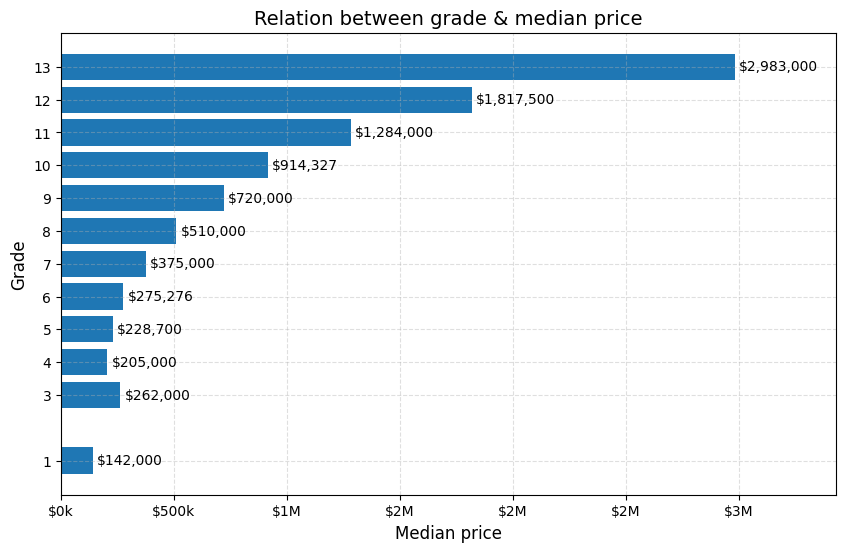

In [ ]:
# set size of the figure
fig, ax = plt.subplots(figsize=(10, 6))

# count median price for each grade
median_price = df.groupby('grade')['price'].median().reset_index()

# create horizontal plot
ax.barh(median_price["grade"], median_price["price"], align='center')

# set unit of x-axis
ax.xaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# show exact values
ax.bar_label(
    ax.containers[0],
    fmt=lambda x: f"${x:,.0f}",
    padding=3)

# show each grade separately
ax.set_yticks(median_price["grade"])

# horizontal plot settings
ax.set_title('Relation between grade & median price', fontsize=14)
ax.set_xlabel('Median price', fontsize=12)
ax.set_ylabel('Grade', fontsize=12)
ax.margins(x=0.15)

plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


Below there is a mosaic plot combining variables related to bedrooms and bathroooms. Since bathrooms from the database have various fractional values, **the number of bathrooms has been rounded to the closest integer** in order to improve plot readability. Outliers have also been ignored.

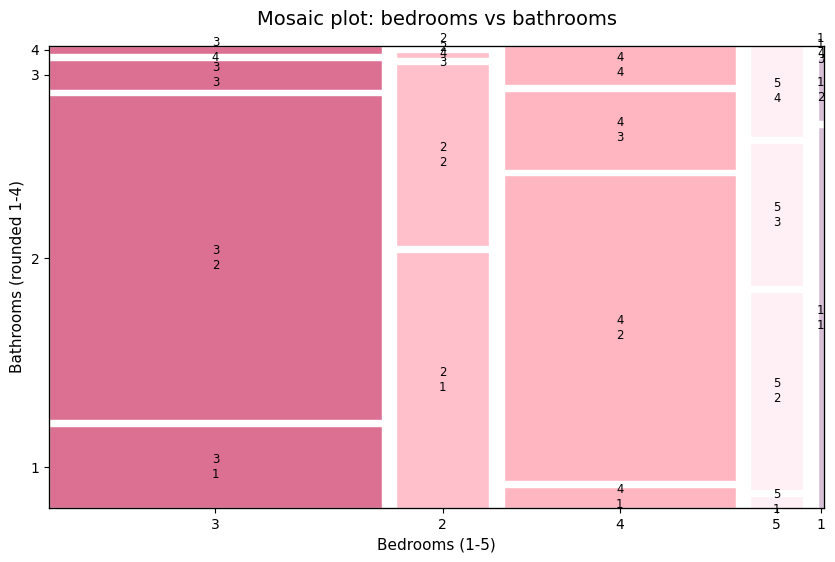

In [ ]:
#b)

from statsmodels.graphics.mosaicplot import mosaic

# set size of the figure
# fig - figure, ax - axes
fig, ax = plt.subplots(figsize=(10, 6))

# copy data with rounded number of bathrooms
df_clean = df.copy()
df_clean["bathrooms_round"] = df_clean["bathrooms"].round().astype(int)

# get rid of rare edge cases
# keep only houses with 1-5 bedrooms & 1-4 bathrooms
df_clean = df_clean[
    (df_clean["bedrooms"].between(1, 5))
    & (df_clean["bathrooms_round"].between(1, 4))
]

# set colors for mosaic plot
colors_dict = {
    1: "thistle",
    2: "pink",
    3: "palevioletred",
    4: "lightpink",
    5: "lavenderblush",
}

# create mosaic plot
mosaic(
    df_clean,
    ["bedrooms", "bathrooms_round"],
    ax=ax,
    gap=0.02,
    properties=lambda key: {
        "facecolor": colors_dict.get(int(key[0]), "gray"),
        "edgecolor": "white",
    },
)

# mosaic settings
plt.title("Mosaic plot: bedrooms vs bathrooms", fontsize=14, pad=15)
ax.set_xlabel("Bedrooms (1-5)", fontsize=11)
ax.set_ylabel("Bathrooms (rounded 1-4)", fontsize=11)

plt.show()


As can be seen on the graph above, houses most commonly have 3 bedrooms and 1-2 bathrooms or 4 bedrooms and 2 bathrooms. Quite less common apartments have 2 bedrooms and 1-2 bathrooms.

## Exercise 4
"I am interested in the house with 3 bedrooms, 2 bathrooms and 2 floors"  
a) Compute the basic statistics of apartments fulfilling above constraints.  
b) Distinct accepted apartments on any of previously created plots.  
c) Find such apartments with best price to footage ratio.  

In [ ]:
#a)

df_query = df.loc[(df["bedrooms"] == 3) & (df["bathrooms"] == 2) & (df["floors"] == 2)]

print(f"Number of houses: {df_query.shape[0]}")


Number of houses: 154


In [ ]:
df_query.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,1.540000e+02,1.540000e+02,154.0,154.0,154.000000,154.000000,154.0,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000,154.000000
mean,4.397177e+09,5.144986e+05,3.0,2.0,1850.279221,23678.948052,2.0,0.006494,0.357143,3.435065,7.551948,1717.422078,132.857143,1969.779221,284.863636,98085.577922,47.567376,-122.247091,1802.337662,17545.123377
std,2.849813e+09,2.497661e+05,0.0,0.0,547.585413,83324.024708,0.0,0.080582,0.919495,0.713322,0.832684,527.473851,248.092631,34.654456,700.057328,48.808788,0.143221,0.150507,453.210930,40404.134611
min,7.600057e+06,2.090000e+05,3.0,2.0,1020.000000,700.000000,2.0,0.000000,0.000000,2.000000,6.000000,720.000000,0.000000,1900.000000,0.000000,98001.000000,47.194700,-122.519000,850.000000,886.000000
25%,2.060901e+09,3.769750e+05,3.0,2.0,1452.500000,3414.750000,2.0,0.000000,0.000000,3.000000,7.000000,1402.500000,0.000000,1942.250000,0.000000,98038.500000,47.498800,-122.361750,1452.500000,4020.000000
50%,3.630010e+09,4.640000e+05,3.0,2.0,1700.000000,5868.500000,2.0,0.000000,0.000000,3.000000,7.000000,1625.000000,0.000000,1984.500000,0.000000,98103.000000,47.584750,-122.299500,1725.000000,6278.000000
75%,7.184074e+09,5.894625e+05,3.0,2.0,2127.500000,10800.250000,2.0,0.000000,0.000000,4.000000,8.000000,1977.500000,207.500000,1997.500000,0.000000,98122.000000,47.682400,-122.149250,2117.500000,10392.250000
max,9.829200e+09,1.755000e+06,3.0,2.0,3650.000000,843309.000000,2.0,1.000000,4.000000,5.000000,10.000000,3650.000000,1120.000000,2014.000000,2014.000000,98199.000000,47.777000,-121.709000,3170.000000,273992.000000


There are 154 houses that satisfy given conditions.

A typical house created from all median values would cost $464,000. It would have 1,700 square feet of living area, consist of 2 floors (with 1,625 square feet above ground level) and 10,800 square feet of land space. It would have 3 bedrooms and 2 bathrooms, but it wouldn't have a basement. It would not be overlooking the waterfront and the view of the property would be marked as 0 out of 4.

That hypothetical house would have been built in 1997-1998 and hasn't been renovated since. The grade of the house would be 7 and its condition would be accessed as 3 out of 5. The square footage of interior housing living space for the nearest 15 neighbors would be slightly higher (1,725 square feet) and square footage of their land space would be significantly lower (6,278 square feet).

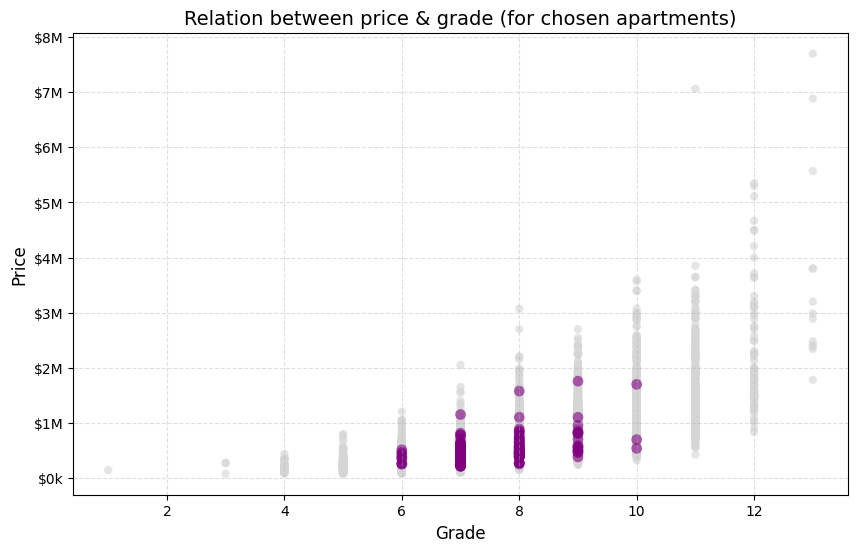

In [ ]:
#b)

# set size of the figure
plt.figure(figsize=(10, 6))

# create scatter plot for all houses
plt.scatter(
    df["grade"],
    df["price"],
    alpha=0.6,
    color="#d5d5d5",
    edgecolors="none"
)

# add data from the query to scatter plot
plt.scatter(
    df_query["grade"].astype(int),
    df_query["price"],
    alpha=0.6,
    color="purple",
    edgecolors="none",
    s=60,
    label="Accepted apartments (3 bed, 2 bath, 2 fl)",
)

# set unit of y-axis
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_price))

# scatter plot settings
plt.title("Relation between price & grade (for chosen apartments)", fontsize=14)
plt.xlabel("Grade", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.4)

plt.show()


As can be seen on the graph above, houses that satisfy these conditions happen to be in the middle range of grades of the available houses in the city. Luckily, most of the results tend to cluster in the lower range of the price for the corresponding grade.

In [ ]:
# get price to footage ratio
price_to_footage = df_query["price"] / df_query["sqft_living"]

# get indices of best houses sorted by ratio (in ascending order)
df_best_idx = price_to_footage.sort_values().index

# get 5 best houses
df_query.loc[df_best_idx].head(5)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
9704,7452500565,20140829T000000,260000.0,3,2.0,2710,5000,2.0,0,0,...,6,2710,0,1951,0,98126,47.5188,-122.373,850,5000
11258,7937600262,20140710T000000,379900.0,3,2.0,3110,44967,2.0,0,0,...,9,3020,90,1999,0,98058,47.4343,-122.082,2150,44967
19880,3832050860,20150319T000000,210000.0,3,2.0,1580,4961,2.0,0,0,...,7,1580,0,2006,0,98042,47.3338,-122.053,2280,5000
16014,5104450440,20141113T000000,252500.0,3,2.0,1810,10684,2.0,0,0,...,8,1810,0,1987,0,98058,47.4619,-122.153,2140,9657
20906,3355400242,20141028T000000,274900.0,3,2.0,1936,6612,2.0,0,0,...,7,1936,0,2014,0,98001,47.2602,-122.246,1620,21600


As can be seen in the table above, the houses with the best price to footage ratio that also satisfy given conditions are significantly cheaper comparing to the median price. The house having the best ratio is actually the second cheapest house from the top 5 houses.

These houses also have much greater square footage than the median, all of them have the expected number of bedrooms and bathrooms, and one of them even has a basement.